# Datos y target

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

from src import config, eda, utils, pipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## Archivos

In [2]:
rows = []
for key in config.FILES:
    path = utils.raw_file(key)
    if path is None:
        continue
    if path.suffix == ".parquet":
        pf = pq.ParquetFile(path)
        n, cols = pf.metadata.num_rows, [utils.normalize_name(c) for c in pf.schema_arrow.names]
    else:
        cols = [utils.normalize_name(c) for c in pd.read_csv(path, nrows=1).columns]
        with open(path, "rb") as f:
            n = sum(1 for _ in f) - 1
    rows.append({"archivo": path.name, "filas": n, "columnas": len(cols), "primeras": ", ".join(cols[:6])})
pd.DataFrame(rows)

,archivo,filas,columnas,primeras
0,y_train.csv,358487,2,"key_value, target"
1,sample_submission.csv,396666,2,"key_value, target"
2,productos.csv,42,2,"name_product, producto"
3,rcc_train.csv,30391626,9,"codmes, key_value, condicion, tipo_credito, co..."
4,rcc_test.csv,34351754,9,"codmes, key_value, condicion, tipo_credito, co..."
5,sunat_train.csv,1462036,18,"key_value, tipcontribuyente, tippersona, ciiu,..."
6,sunat_test.csv,1687128,18,"key_value, tipcontribuyente, tippersona, ciiu,..."
7,se_train.csv,358428,15,"key_value, edad, sexo, est_cvl, sit_lab, cod_ocu"
8,se_test.csv,396609,15,"key_value, edad, sexo, est_cvl, sit_lab, cod_ocu"
9,censo_train.csv,153139,256,"key_value, lon_x, lat_y, zon_sis, zon_der, zon..."


## Target

clientes: 358,487 | defaults: 56,710 | tasa: 15.82%


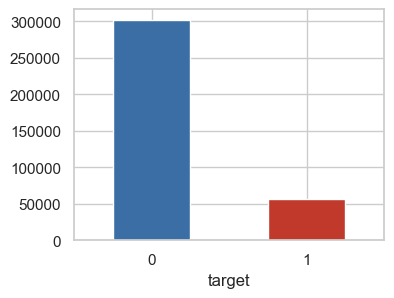

In [3]:
y = utils.load_target()
print(f"clientes: {len(y):,} | defaults: {int(y.sum()):,} | tasa: {y.mean():.2%}")
y.value_counts().sort_index().plot.bar(figsize=(4, 3), color=["#3b6ea5", "#c0392b"])
plt.xticks(rotation=0)
plt.show()

## Cobertura por fuente

In [4]:
test_keys = set(utils.load_raw("sample_submission").iloc[:, 0])
base = {"train": set(y.index), "test": test_keys}
rows = []
for src in ["rcc", "sunat", "se", "censo"]:
    for split in ["train", "test"]:
        path = utils.raw_file(f"{src}_{split}")
        if path is None:
            continue
        have = set(utils.read_column(path, "key_value").unique())
        rows.append({"fuente": src, "split": split, "clientes": len(have & base[split]),
                     "cobertura_%": round(100 * len(have & base[split]) / len(base[split]), 1)})
pd.DataFrame(rows)

,fuente,split,clientes,cobertura_%
0,rcc,train,358487,100.0
1,rcc,test,396666,100.0
2,sunat,train,233866,65.2
3,sunat,test,253803,64.0
4,se,train,358428,100.0
5,se,test,396609,100.0
6,censo,train,153139,42.7
7,censo,test,200499,50.5


## Meses del RCC

train: 201703 a 201802 | mes de desembolso 201802 | filas previas: 27,140,446 de 30,391,626
test: 201803 a 201902 | mes de desembolso 201902 | filas previas: 30,683,250 de 34,351,754


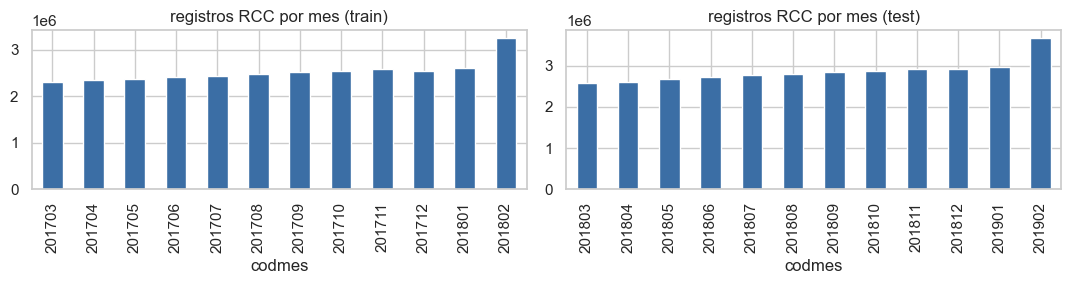

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, split in zip(axes, ["train", "test"]):
    path = utils.raw_file(f"rcc_{split}")
    counts = utils.read_column(path, "codmes").value_counts().sort_index()
    counts.plot.bar(ax=ax, color="#3b6ea5")
    ref = config.REF_MONTH[split]
    print(f"{split}: {counts.index.min()} a {counts.index.max()} | mes de desembolso {ref} | filas previas: {counts[counts.index < ref].sum():,} de {counts.sum():,}")
    ax.set_title(f"registros RCC por mes ({split})")
plt.tight_layout()
plt.show()